# Projet : POKEDEX
objectif : créer une application Python offrant les fonctionnalités d'un pokédex

Les fonctionnalités à implémenter : 
- analyse et classifier les Pokémons
- prédire certaines propriétés

Jeu de données : 
- fichier csv "pokemon" (caractéristiques) :  https://www.kaggle.com/code/melearning-with-pokemon-predicting-legend/input?select=pokemon.csv
- banque d'image pokémon (1er gen) :  https://www.kaggle.com/datasets/mikoajkolman/pokemon-images-first-generation17000-files

### Rendue
- Notebook/code
- rapport : 
    - méthodo. adoptée
    - différentes méthodes et modèles testés
    - résultats + analyses/interprétations
    - limites approche + améliorations possibles

In [24]:
print("Hello, World!")

Hello, World!


In [25]:
pip install scikit-learn

You should consider upgrading via the '/Users/lina.colinot/Desktop/Maths IA/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [26]:
pip install matplotlib

You should consider upgrading via the '/Users/lina.colinot/Desktop/Maths IA/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [27]:
pip install numpy

You should consider upgrading via the '/Users/lina.colinot/Desktop/Maths IA/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [28]:
pip install pandas

You should consider upgrading via the '/Users/lina.colinot/Desktop/Maths IA/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## Niveau 1 : Données tabulaires

But : 
clustering : identifier les groupes + interprédation
statistiques de base => légendaire ou non + type du pokémon

A implémenter dans l'affichage: 
- groupe du Pokémon
- légendaire ou non

Tester plus. méthodes et justifier choix du modèle (comparaison du modèle)

Donnée 'pokémon.csv'

| Features name | Features' type |
| - | - |
|# | Float|
| Name | String 
Type 1 | String 
Type 2 | String 
HP | Float
Attack | Float
Defense | Float
Sp. Atk | Float
Sp. Def | Float
Speed | Float
Generation | Float
Legendary | Bool

[ Méthode à développer d'après Claude.com ]
1. Prétraitement des données : 
- entrées : stats
- cibles : types / légendaire
- séparation des données
2. Clustering
- différentes méthodes d'après stats
- choix nombre de clusters
- interprétation clusters (légendaire/types)
3. Classification 
4. Comparaison



In [29]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
# Importation des données

data = pd.read_csv('pokemon.csv', index_col="#")


# Prétraitement
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
y_leg, y_type = data["Legendary"].astype("int8"), data["Type 1"]

# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(data[stats])


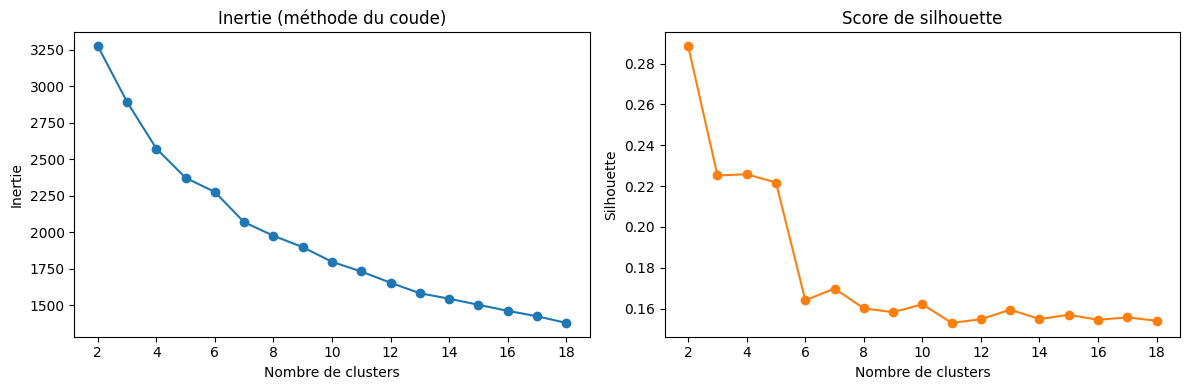

In [30]:
# K-means clustering

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Détermination du nombre de clusters optimal
inertias = []
score = []

for k in range(2, 19):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_) # Méthode du coude 
    score.append(silhouette_score(X, kmeans.fit_predict(X))) # Score de silhouette


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(2, 19), inertias, marker="o")
axes[0].set_title("Inertie (méthode du coude)")
axes[0].set_xlabel("Nombre de clusters")
axes[0].set_ylabel("Inertie")

axes[1].plot(range(2, 19), score, marker="o", color="tab:orange")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

D'après la méthode du coude et de la silhoutte, on repère que le nombre optimal de cluster est soit de 4 ou de 6

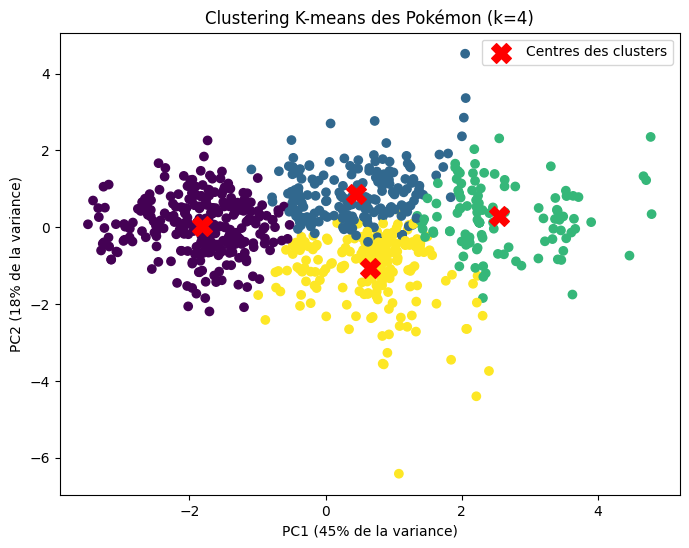

In [31]:
# Clustering avec le nombre de clusters optimal (k=6)
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(X)
labels = kmeans.predict(X)

# Projection sur les axes principaux
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)                       # X doit être standardisé
centres_pca = pca.transform(kmeans.cluster_centers_)

# Visualisation des clusters
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
plt.scatter(centres_pca[:, 0], centres_pca[:, 1], c='red', marker='X', s=200, label='Centres des clusters')
plt.title("Clustering K-means des Pokémon (k=4)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la variance)")
plt.legend()
plt.show()



In [32]:
# Analyse et interprétation des clusters

#Création d'un tableau récapitulatif des clusters 

data_clusters = data.copy()

# Ajout d'une colonne "Cluster" avec le numéro de cluster de chaque Pokémon

data_clusters["Cluster"] = labels

#Affichage du nombre de Pokémon par cluster
# Value counts compte combien de fois chaque valeur de cluster apparaît
# Sort index classe les résultats par ordre croissant de clusterts dans l'ordre des numéros de clusters

print(data_clusters["Cluster"].value_counts().sort_index())


Cluster
0    283
1    202
2    115
3    200
Name: count, dtype: int64


In [33]:
# Calcul des stats moyennes pour chaque cluster ( pour interpréter les caractéristiques principales des clusters)


# Regrouper tous les poké qui appartiennent à un même cluster et calculer la moyenne des stats pour chaque cluster 
moyennes_clusters = data_clusters.groupby("Cluster")[stats].mean()

# Arrondir à deux décimales

moyennes_clusters.round(2)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
Cluster,,,,,,
0,50.11,53.98,51.89,48.06,49.21,49.45
1,69.29,84.31,65.91,83.52,73.04,94.62
2,94.30,114.02,94.57,117.65,103.69,95.45
3,81.92,88.92,101.00,71.26,84.58,52.68


Interprétation : 

Cluster 0 = Pokémon aux statistiques globalement faibles ( toutes les moyennes aux alentours de 50 )
Cluster 1 = Pokémon rapides
Cluster 2 = Statistiques globalement élevées ( meilleurs moyennes sauf en défense ), Pokémon particulièrement offensifs ( attaque et attaque spéciale +++ )
Cluster 3 = Pokémon défensifs

In [34]:
# Classification supervisée
# Pokémon légendaire ou non légendaire ?

X_leg = data[stats]
#X contient les 6 stats de chaque pokémon
Y_leg = data["Legendary"].astype("int")
#Y contient la réponse (1 si légendaire, 0 sinon)

print(X_leg.shape)
print(Y_leg.shape)

(800, 6)
(800,)


In [36]:
# Sépare les données pour entraînement puis test
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_leg, Y_leg, test_size=0.2, random_state=42,
    stratify=Y_leg
)
# Stratify sert à conserver approximativement la même proportion de poké légendaires et non légendaires dans les deux ensembles (train et test)

print(X_train.shape)
print(X_test.shape)

(640, 6)
(160, 6)


In [ ]:
# Import et entraînement du modèle KNN à 3 voisins
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, Y_train)

KNeighborsClassifier(n_neighbors=3)

In [39]:
model.score(X_test, Y_test)

0.93125

In [ ]:
# Voir les prédictions que le modèle a réellement faites
Y_pred = model.predict(X_test)
print(Y_pred)

[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0
 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0]


In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#On apprend la normalisation sur les données d'entraînement puis on applique cette même normalisation aux données de test
# Il est important de séparer les données avant de normaliser, sinon les données de test influencent la normalisation ( = fuite de données)

In [42]:
# on fait un KNN avec trois voisins et normalisations pour comparer au KNN à 3 voisins sans normalisation

model_scaled_3 = KNeighborsClassifier(n_neighbors=3)

model_scaled_3.fit(X_train_scaled, Y_train)
model_scaled_3.score(X_test_scaled, Y_test)


0.93125

In [43]:
model_scaled_6 = KNeighborsClassifier(n_neighbors=6)

model_scaled_6.fit(X_train_scaled, Y_train)
model_scaled_6.score(X_test_scaled, Y_test)

0.925

Nous avons testé trois modèles KNN pour prédire si un Pokémon est légendaire ou non à partir de ses statistiques de combat. Nous avons modifié deux paramètres : des données normalisées ou non, et le nombre de voisins (3 ou 6). Les paramètres ont été modifiés un par un afin de pouvoir observer leur effet sur les résultats.

Observations suite aux tests KNN :

1/ La normalisation n'a pas modifié l'accuracy pour le KNN à 3 voisins
2/ Le passage de 3 à 6 voisins a légèrement diminué l'accuracy ( de 93,125% à 92,5%)


In [12]:
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer

ct = ColumnTransformer(
    transformers=[
        ("encoder", OrdinalEncoder(), ["Type 1", "Type 2"]),
        
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

# Voir avec ColumTransformer pour encoder les colonnes catégorielles

data_num = ct.fit_transform(data_mod)
print(ct.named_transformers_['encoder'].categories_)
pd.DataFrame(data_num, columns=ct.get_feature_names_out())

NameError: name 'data_mod' is not defined

## Niveau 2 : Classification à partir d'images

But : dvlper modèle Ml pour identifier type d'un Pokémon à partir d'une image

Image d'un pokemon => le/les type(s)


## Niveau 3 : Pokédex complet

But : application Pokédex complet

Implémentations : 
- niveau 1
- niveau 2
- fonctionnalités trie par type
- utilisation caméra ordi : image de pokémon